# Modèle de Vasicek — Théorie, Simulation, Calibration et Applications

Ce notebook explore le **modèle de Vasicek**, un modèle stochastique classique de taux d'intérêt introduit par Oldřich Vašíček en 1977. C'est l'un des premiers modèles à décrire l'évolution du **taux court** `r(t)` comme un processus à **retour à la moyenne** (mean-reverting).

## Équation différentielle stochastique (EDS)

Le modèle est défini par l'EDS suivante :

$$
dr(t) = a\,(b - r(t))\,dt + \sigma\,dW(t)
$$

où :
- $r(t)$ : taux d'intérêt court terme à l'instant $t$
- $a > 0$ : **vitesse de retour à la moyenne** (mean-reversion speed)
- $b$ : **niveau moyen de long terme** (long-term mean)
- $\sigma > 0$ : **volatilité** du taux
- $W(t)$ : un **mouvement brownien standard** (processus de Wiener)

##  Interprétation intuitive

- Le terme $a(b - r(t))$ est le **terme de rappel** : si $r(t) < b$, il pousse le taux vers le haut ; si $r(t) > b$, il le pousse vers le bas.
- Plus $a$ est grand, plus le retour est **rapide**.
- Le terme $\sigma\,dW(t)$ ajoute du **bruit aléatoire** (fluctuations).

##  Propriétés théoriques clés

1. **Solution explicite** :
$$
r(t) = r_0 e^{-at} + b(1 - e^{-at}) + \sigma \int_0^t e^{-a(t-s)} dW(s)
$$

2. **Distribution** : $r(t)$ suit une **loi normale** :
$$
r(t) \sim \mathcal{N}\big(m(t),\, v(t)\big)
$$
avec
$$
m(t) = r_0 e^{-at} + b(1 - e^{-at}), \quad
v(t) = \frac{\sigma^2}{2a}(1 - e^{-2at})
$$

3. **Variance stationnaire** (quand $t \to \infty$) :
$$
v_\infty = \frac{\sigma^2}{2a}
$$

4. **Taux long terme** $R_\infty$ (rendement asymptotique d'un zéro-coupon) :
$$
R_\infty = b - \frac{\sigma^2}{2a^2}
$$

##  Paramètres utilisés dans ce notebook

| Paramètre | Valeur | Rôle |
|-----------|--------|------|
| $r_0$     | 3 %    | Taux court initial |
| $a$       | 0,5    | Vitesse de rappel |
| $b$       | 4 %    | Niveau long terme |
| $\sigma$  | 1 %    | Volatilité |
| $T$       | 10 ans | Horizon de simulation |

##  Objectifs du notebook

1. Simuler des trajectoires du taux court (schéma exact et Euler).
2. Comparer empiriquement à la loi théorique (moments, histogrammes).
3. Étudier l'impact de $a$ et $\sigma$.
4. Calibrer le modèle sur des courbes de taux réelles (mesure $P$ et $Q$).
5. Pricer obligations, swaps et options sur zéro-coupon.
6. Discuter des **limites** du modèle (taux négatifs, rigidité, instabilité).

In [3]:
from pathlib import Path
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src" / "__init__.py").is_file():
    project_root = project_root.parent
if not (project_root / "src" / "__init__.py").is_file():
    raise FileNotFoundError("Could not locate the project root containing src/__init__.py")
sys.path.insert(0, str(project_root))

from src.bonds import cashflows
from src.curve import bootstrap_par_curve, price_with_curve, par_on_annual_grid
from src.swap import swap_schedule, par_swap_rate
from src.vasicek import *

r0, a, b, sigma = 0.03, 0.5, 0.04, 0.01
T, n_steps, n_paths = 10, 500, 5000

print(f"Écart-type stationnaire : {sigma / np.sqrt(2 * a):.4f}")
print(f"Demi-vie du rappel      : {np.log(2) / a:.2f} an(s)")
print(f"Taux long terme R_inf   : {b - sigma**2 / (2 * a**2):.4%}")

Écart-type stationnaire : 0.0100
Demi-vie du rappel      : 1.39 an(s)
Taux long terme R_inf   : 3.9800%


## Simulation du taux court et vérification des moments théoriques

Nous simulons 5000 trajectoires du taux court sur 10 ans, puis nous comparons la moyenne et l'écart-type empiriques aux formules théoriques :

$$
m(t) = r_0 e^{-at} + b(1 - e^{-at}), \qquad
s(t) = \sqrt{\frac{\sigma^2}{2a}(1 - e^{-2at})}
$$

### Ce que l'on attend

- **Moyenne** : part de $r_0 = 3\%$ et tend vers $b = 4\%$ exponentiellement.
- **Écart-type** : part de 0 (à $t=0$) et tend vers $\sigma/\sqrt{2a} \approx 1\%$.
- La bande ±2 écarts-types englobe ~95% des trajectoires.

### Ce que montre le graphique

- Lignes fines : 15 trajectoires simulées.
- Ligne noire épaisse : moyenne théorique.
- Zone grise : ±2 écarts-types théoriques.
- Ligne rouge pointillée : niveau long terme $b$.

C'est un excellent test visuel de la **cohérence entre simulation et théorie**.

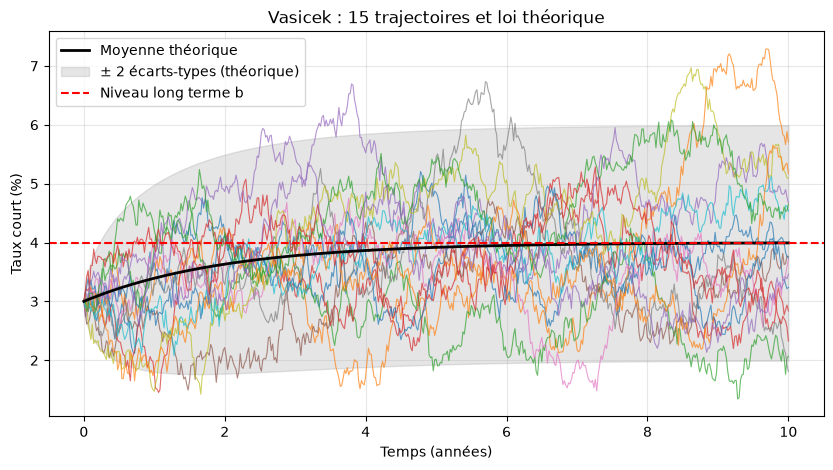

In [4]:
t, r = simulate_vasicek(r0, a, b, sigma, T, n_steps, n_paths, seed=42)

mean_t = vasicek_mean(t, r0, a, b)
sd_t = np.sqrt(vasicek_var(t, a, sigma))

plt.figure(figsize=(10, 5))
plt.plot(t, 100 * r[:15].T, lw=0.8, alpha=0.7)
plt.plot(t, 100 * mean_t, "k", lw=2, label="Moyenne théorique")
plt.fill_between(t, 100 * (mean_t - 2 * sd_t), 100 * (mean_t + 2 * sd_t),
                 color="gray", alpha=0.2, label="± 2 écarts-types (théorique)")
plt.axhline(100 * b, color="red", ls="--", label="Niveau long terme b")
plt.xlabel("Temps (années)"); plt.ylabel("Taux court (%)")
plt.title("Vasicek : 15 trajectoires et loi théorique")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Distribution de $r(t)$ à différentes dates

Dans le modèle de Vasicek, $r(t)$ suit une **loi normale**. Nous vérifions cela en traçant des histogrammes des simulations à $t = 0{,}5$ an, $2$ ans et $10$ ans, et en les superposant à la densité théorique :

$$
f_{r(t)}(x) = \frac{1}{s(t)\sqrt{2\pi}} \exp\!\left(-\frac{(x - m(t))^2}{2 s(t)^2}\right)
$$

### Observations attendues

- À $t = 0{,}5$ an : distribution **étroite**, centrée entre 3 % et 4 %.
- À $t = 2$ ans : distribution plus large, centrée près de 4 %.
- À $t = 10$ ans : distribution quasi-stationnaire, largeur maximale ≈ 1 %.

L'**accord visuel** entre histogramme et courbe rouge valide la nature gaussienne du modèle.

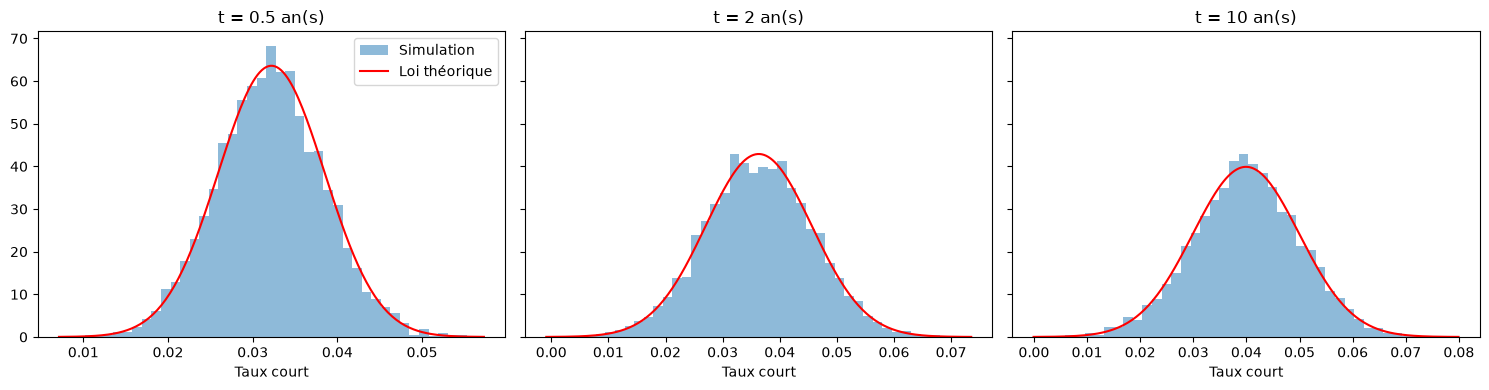

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, date in zip(axes, [0.5, 2, 10]):
    i = int(date / T * n_steps)
    m, s = mean_t[i], sd_t[i]
    xs = np.linspace(m - 4 * s, m + 4 * s, 200)
    pdf = np.exp(-0.5 * ((xs - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
    ax.hist(r[:, i], bins=40, density=True, alpha=0.5, label="Simulation")
    ax.plot(xs, pdf, "r", label="Loi théorique")
    ax.set_title(f"t = {date} an(s)"); ax.set_xlabel("Taux court")
axes[0].legend()
plt.tight_layout(); plt.show()

## Rôle des paramètres $a$ et $\sigma$

### Effet de la vitesse de rappel $a$

- $a$ petit (ex. 0,1) → le taux **dérive lentement** vers $b$.
- $a$ grand (ex. 3,0) → le taux **colle rapidement** à $b$.

La **demi-vie** $\tau_{1/2} = \ln(2)/a$ quantifie cela :
- $a = 0{,}1 \Rightarrow \tau_{1/2} \approx 6{,}9$ ans
- $a = 0{,}5 \Rightarrow \tau_{1/2} \approx 1{,}4$ an
- $a = 3{,}0 \Rightarrow \tau_{1/2} \approx 0{,}23$ an

### Effet de la volatilité $\sigma$

- $\sigma$ petit → trajectoire lisse.
- $\sigma$ grand → trajectoire très agitée.

Mais attention : $\sigma$ affecte aussi $R_\infty = b - \sigma^2/(2a^2)$ :
- $\sigma \uparrow$ ⇒ $R_\infty \downarrow$ (prime de risque plus forte).

Ces deux graphiques donnent une **intuition visuelle** du modèle.

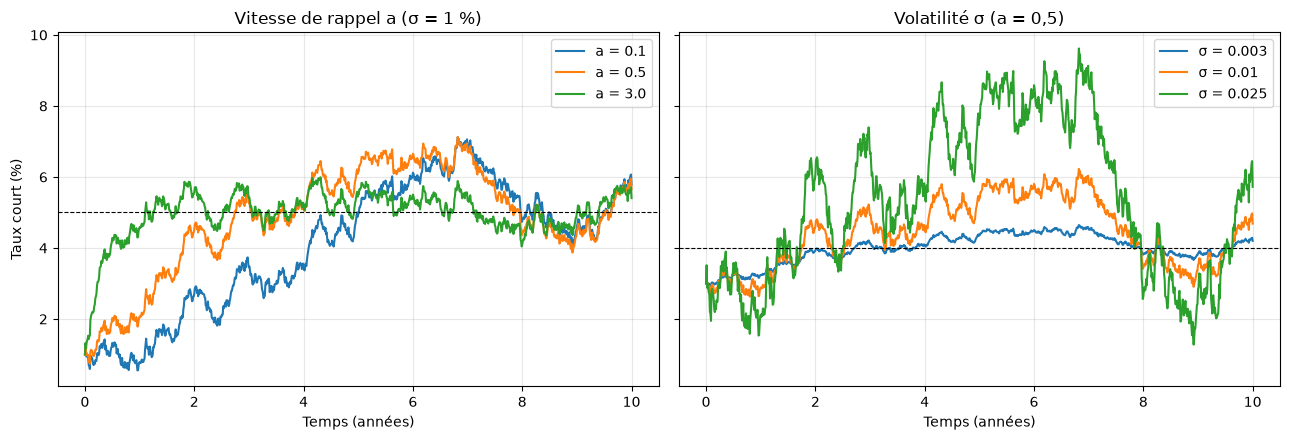

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a_, col in zip([0.1, 0.5, 3.0], ["tab:blue", "tab:orange", "tab:green"]):
    t_, r_ = simulate_vasicek(0.01, a_, 0.05, 0.01, 10, 1000, 1, seed=3)
    axes[0].plot(t_, 100 * r_[0], color=col, label=f"a = {a_}")
axes[0].axhline(5, color="k", ls="--", lw=0.8)
axes[0].set_title("Vitesse de rappel a (σ = 1 %)"); axes[0].legend()

for s_, col in zip([0.003, 0.01, 0.025], ["tab:blue", "tab:orange", "tab:green"]):
    t_, r_ = simulate_vasicek(0.03, 0.5, 0.04, s_, 10, 1000, 1, seed=3)
    axes[1].plot(t_, 100 * r_[0], color=col, label=f"σ = {s_}")
axes[1].axhline(4, color="k", ls="--", lw=0.8)
axes[1].set_title("Volatilité σ (a = 0,5)"); axes[1].legend()
for ax in axes:
    ax.set_xlabel("Temps (années)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Taux court (%)")
plt.tight_layout(); plt.show()

## Schéma exact vs schéma d'Euler — Analyse de l'erreur

Le modèle de Vasicek admet une **solution exacte** entre deux pas de temps :

$$
r_{t+\Delta t} = r_t e^{-a\Delta t} + b(1 - e^{-a\Delta t}) + \sigma \sqrt{\frac{1 - e^{-2a\Delta t}}{2a}}\; Z, \quad Z \sim \mathcal{N}(0,1)
$$

Le schéma d'Euler, lui, **discrétise l'EDS** :

$$
r_{t+\Delta t} \approx r_t + a(b - r_t)\Delta t + \sigma \sqrt{\Delta t}\; Z
$$

### Comparaison

Nous simulons 40 000 trajectoires avec les deux schémas, pour $\Delta t \in \{1,\ 0{,}5,\ 0{,}25,\ 0{,}1,\ 0{,}01\}$, et nous mesurons le **ratio** :

$$
\text{ratio} = \frac{\text{Var empirique à } T=3}{\text{Var théorique}}
$$

### Résultats attendus

| $\Delta t$ | Exact | Euler |
|-----------|-------|-------|
| 1,00      | ≈ 1   | ≈ 12  |
| 0,50      | ≈ 1   | ≈ 2   |
| 0,25      | ≈ 1   | ≈ 1,33 |
| 0,01      | ≈ 1   | ≈ 1,01 |

Le schéma exact est **toujours précis**. Le schéma d'Euler **converge lentement** (erreur $O(\Delta t)$ en biais, $O(\sqrt{\Delta t})$ en bruit).

In [7]:
a_test = 2.0
true_var = vasicek_var(3, a_test, sigma)
rows = []
for n in [3, 6, 12, 30, 300]:                       # dt = 1, 0,5, 0,25, 0,1, 0,01
    _, r_ex = simulate_vasicek(r0, a_test, b, sigma, 3, n, 40000, seed=0, scheme="exact")
    _, r_eu = simulate_vasicek(r0, a_test, b, sigma, 3, n, 40000, seed=0, scheme="euler")
    rows.append({"dt": 3 / n,
                 "var exact / théorique": r_ex[:, -1].var() / true_var,
                 "var Euler / théorique": r_eu[:, -1].var() / true_var})
pd.DataFrame(rows).round(4)

,dt,var exact / théorique,var Euler / théorique
0,1.00,1.0090,11.9179
1,0.50,1.0054,2.0024
2,0.25,0.9955,1.3251
3,0.10,0.9914,1.1009
4,0.01,1.0015,1.0117


## Probabilité d'un taux négatif — Une limite du modèle

Comme $r(t)$ suit une loi normale, il y a **toujours** une probabilité non nulle que $r(t) < 0$ :

$$
\mathbb{P}(r(t) < 0) = \Phi\!\left(-\frac{m(t)}{s(t)}\right)
$$

où $\Phi$ est la fonction de répartition de la loi normale centrée réduite.

### Expérience

Nous prenons :
- $r_0 = 1\%$ (niveau bas)
- $a = 0{,}5$
- $b = 2\%$ (niveau long terme bas)
- $\sigma = 1{,}5\%$ (volatilité élevée)

Puis nous traçons $\mathbb{P}(r(t) < 0)$ en fonction de $t$.

### Message important

- Le modèle **autorise des taux négatifs**, ce qui est **irréaliste** dans beaucoup de contextes économiques.
- C'est une **limite majeure** de Vasicek.
- Les modèles **CIR** (Cox-Ingersoll-Ross) ou **Black-Karasinski** corrigent cela (mais avec d'autres inconvénients).

Cette cellule est une excellente introduction aux extensions du modèle.

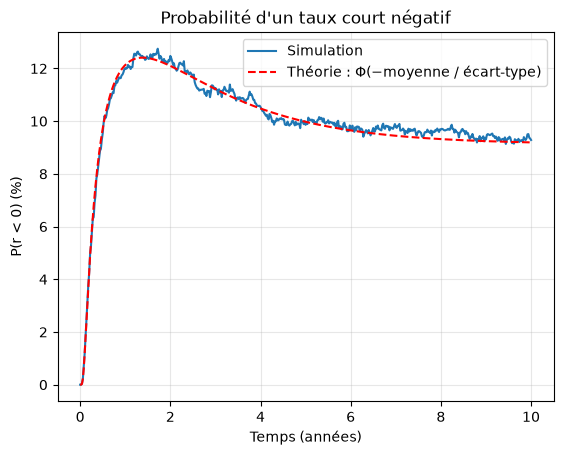

In [8]:
r0n, an, bn, sn = 0.01, 0.5, 0.02, 0.015                 # niveau bas, volatilité plus forte
t_n, r_n = simulate_vasicek(r0n, an, bn, sn, 10, 500, 20000, seed=7)

emp = (r_n < 0).mean(axis=0)
theo = [0.5 * (1 + math.erf(-vasicek_mean(x, r0n, an, bn) /
                            np.sqrt(vasicek_var(x, an, sn)) / np.sqrt(2))) if x > 0 else 0.0
        for x in t_n]

plt.plot(t_n, 100 * emp, label="Simulation")
plt.plot(t_n, 100 * np.array(theo), "r--", label="Théorie : Φ(−moyenne / écart-type)")
plt.xlabel("Temps (années)"); plt.ylabel("P(r < 0) (%)")
plt.title("Probabilité d'un taux court négatif"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## Prix d'un zéro-coupon : formule analytique vs Monte-Carlo

Dans Vasicek, le prix d'un zéro-coupon à maturité $T$ admet une **formule fermée** (structure affine) :

$$
P(0,T) = A(T)\,e^{-B(T)\,r_0}
$$

avec
$$
B(T) = \frac{1 - e^{-aT}}{a}, \qquad
\ln A(T) = \left(b - \frac{\sigma^2}{2a^2}\right)(B(T) - T) - \frac{\sigma^2 B(T)^2}{4a}
$$

### Objectif

Vérifier que **la formule analytique** et **l'estimation Monte-Carlo** donnent les mêmes résultats.

- `vasicek_zc_price(...)` : formule fermée (instantanée, exacte).
- `mc_zero_price(...)` : simulation Monte-Carlo (avec erreur-type).

### Tableau de résultats

On affiche :

| Maturité | Formule | Monte-Carlo | Erreur std | Écart / erreur std |
|----------|---------|-------------|------------|---------------------|
| 1 an     | ...     | ...         | ...        | ≈ ±1                |
| 2 ans    | ...     | ...         | ...        | ≈ ±1                |
| 5 ans    | ...     | ...         | ...        | ≈ ±1                |
| 10 ans   | ...     | ...         | ...        | ≈ ±1                |

Un écart normalisé de l'ordre de ±1 est **statistiquement acceptable** : les deux méthodes coïncident.

In [9]:
rows = []
for T_ in [1, 2, 5, 10]:
    exact = vasicek_zc_price(r0, a, b, sigma, T_)
    mc, se = mc_zero_price(r0, a, b, sigma, T_, n_steps=50 * T_, n_paths=20000, seed=0)
    rows.append({"maturité": T_, "formule": exact, "Monte Carlo": mc,
                 "erreur std": se, "écart / erreur std": (mc - exact) / se})
pd.DataFrame(rows).round(5)

,maturité,formule,Monte Carlo,erreur std,écart / erreur std
0,1,0.96839,0.96836,0.00003,-0.89516
1,2,0.93492,0.93486,0.00008,-0.86874
2,5,0.83429,0.83431,0.00018,0.14550
3,10,0.68473,0.68498,0.00026,0.96813


## Formes de la courbe des taux zéro-coupon

Le taux zéro continu pour une maturité $\tau$ est :

$$
R(0,\tau) = -\frac{\ln P(0,\tau)}{\tau} = \frac{B(\tau)\,r_0 - \ln A(\tau)}{\tau}
$$

où $B(\tau)$ et $A(\tau)$ sont définis ci-dessus.

### Comportement asymptotique

Quand $\tau \to \infty$, on montre que :

$$
R(0,\tau) \longrightarrow R_\infty = b - \frac{\sigma^2}{2a^2}
$$

### Trois formes classiques de courbe

Selon la position de $r_0$ par rapport à $R_\infty$ :

| Cas | Forme de la courbe |
|-----|--------------------|
| $r_0 < R_\infty$ | **croissante** (normale / pentue) |
| $r_0 = R_\infty$ | **plate** |
| $r_0 > R_\infty$ | **décroissante** (inversée) |

C'est un des **avantages** de Vasicek : il peut reproduire ces trois formes avec un seul jeu de paramètres.

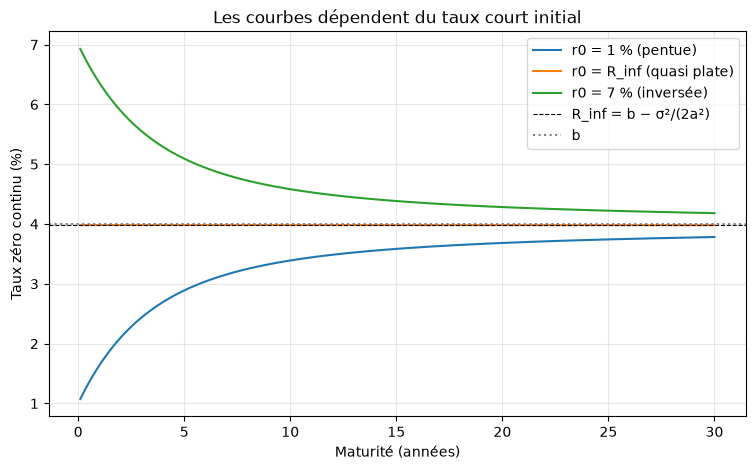

In [10]:
taus = np.linspace(0.1, 30, 300)
r_inf = b - sigma**2 / (2 * a**2)

plt.figure(figsize=(9, 5))
for r_start, label in [(0.01, "r0 = 1 % (pentue)"), (r_inf, "r0 = R_inf (quasi plate)"),
                       (0.07, "r0 = 7 % (inversée)")]:
    plt.plot(taus, 100 * vasicek_zero_rate(r_start, a, b, sigma, taus), label=label)
plt.axhline(100 * r_inf, color="k", ls="--", lw=0.8, label="R_inf = b − σ²/(2a²)")
plt.axhline(100 * b, color="gray", ls=":", label="b")
plt.xlabel("Maturité (années)"); plt.ylabel("Taux zéro continu (%)")
plt.title("Les courbes dépendent du taux court initial"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## Sensibilité au taux court : le rôle de $B(\tau)$

Le prix d'un zéro-coupon est :

$$
P(0,\tau) = A(\tau)\,e^{-B(\tau) r_0}
$$

En dérivant par rapport à $r_0$ :

$$
-\frac{\partial \ln P}{\partial r_0} = B(\tau) = \frac{1 - e^{-a\tau}}{a}
$$

### Interprétation

- $B(\tau)$ est la **duration** (au sens de sensibilité au taux court) du zéro-coupon.
- Pour $\tau$ petit : $B(\tau) \approx \tau$ (comportement linéaire, "duration classique").
- Pour $\tau$ grand : $B(\tau) \to 1/a$ (saturation).

### Effet d'un choc de $+1\%$ sur $r_0$

On trace la **variation du taux zéro** (en points de base) due à un choc de $+1\%$ sur $r_0$ :

$$
\Delta R(0,\tau) \approx \frac{B(\tau)}{\tau} \times 100 \text{ pb}
$$

- Sur les **courtes maturités** : le choc est presque entièrement transmis (~100 pb).
- Sur les **longues maturités** : le choc est **amorti** (< 100 pb).

C'est une conséquence directe du **retour à la moyenne** : un choc sur $r_0$ s'estompe avec le temps.

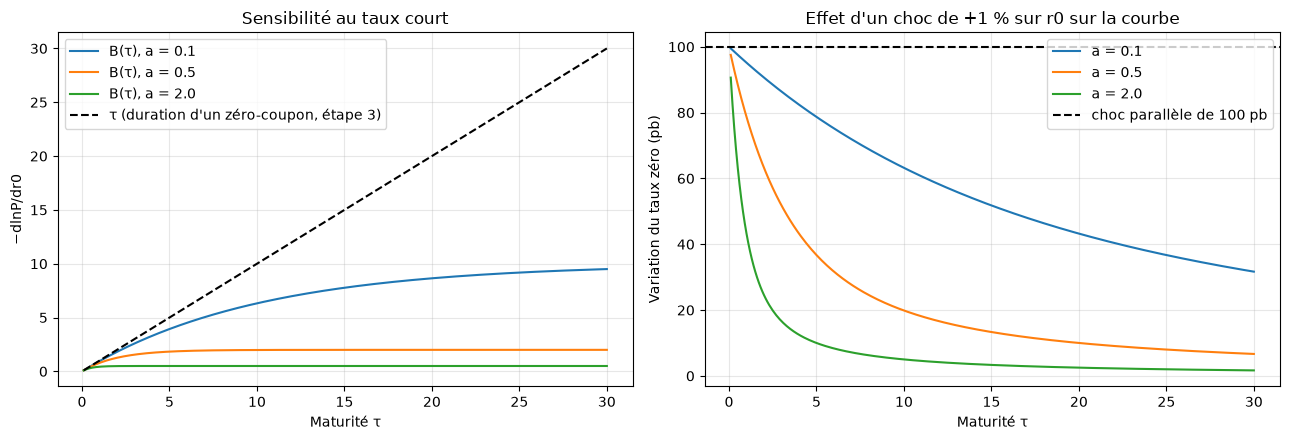

In [11]:
taus = np.linspace(0.1, 30, 300)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for a_ in [0.1, 0.5, 2.0]:
    axes[0].plot(taus, vasicek_B(taus, a_), label=f"B(τ), a = {a_}")
axes[0].plot(taus, taus, "k--", label="τ (duration d'un zéro-coupon, étape 3)")
axes[0].set_xlabel("Maturité τ"); axes[0].set_ylabel("−dlnP/dr0")
axes[0].set_title("Sensibilité au taux court"); axes[0].legend()

for a_ in [0.1, 0.5, 2.0]:
    axes[1].plot(taus, 100 * vasicek_B(taus, a_) / taus * 1.0, label=f"a = {a_}")   # en pb pour +1 % sur r0 : (B/τ)*100 pb
axes[1].axhline(100, color="k", ls="--", label="choc parallèle de 100 pb")
axes[1].set_xlabel("Maturité τ"); axes[1].set_ylabel("Variation du taux zéro (pb)")
axes[1].set_title("Effet d'un choc de +1 % sur r0 sur la courbe"); axes[1].legend()

for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Calibration sur une courbe de taux synthétique

### Objectif

Calibrer les paramètres $(r_0, a, b)$ du modèle Vasicek pour qu'il **colle** à une courbe de taux donnée.

### Données

On utilise une courbe de taux **fictive** (mais réaliste) sur maturités 1 à 10 ans, puis on bootstrap la courbe zéro continue :

$$
R_{\text{mkt}}(\tau) = \ln(1 + z(\tau))
$$

### Méthode de calibration

On minimise le **RMSE** (root mean squared error) :

$$
\text{RMSE}(r_0, a, b) = \sqrt{\frac{1}{n}\sum_{i=1}^n \left(R_{\text{Vasicek}}(\tau_i) - R_{\text{mkt}}(\tau_i)\right)^2}
$$

Le paramètre $\sigma$ est **fixé** (par exemple à 1 %) car il est **mal identifié** sur une seule courbe : plusieurs combinaisons $(a, b, \sigma)$ peuvent donner la même courbe.

### Résultats

- Courbe marché vs courbe Vasicek calibrée.
- Histogramme des erreurs (en pb) : quelques points de base seulement.

Le modèle **colle bien** à la courbe, mais avec un **ajustement structurel** limité (forme paramétrique rigide).

{'a': np.float64(0.25), 'b': np.float64(0.04686), 'sigma': 0.01, 'r0': np.float64(0.02153), 'rmse': np.float64(0.00021)}


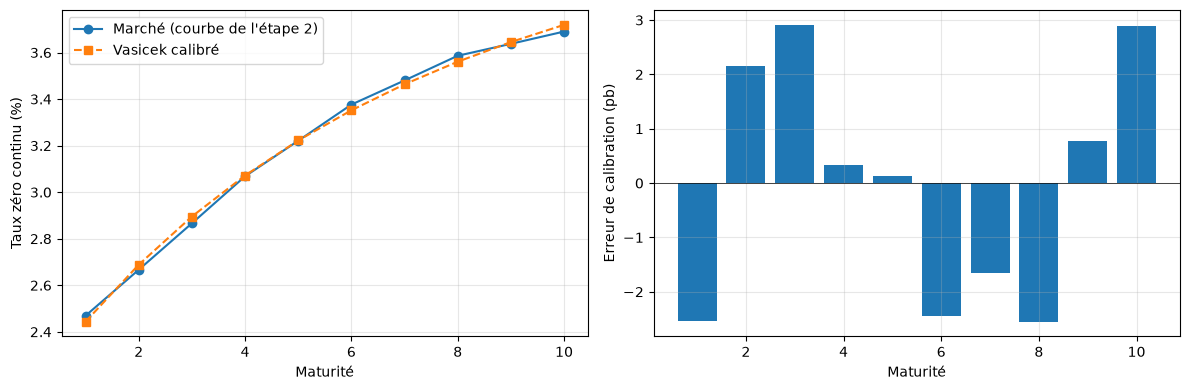

In [12]:
mats = np.arange(1, 11)
par = np.array([0.025, 0.027, 0.029, 0.031, 0.0325, 0.034, 0.035, 0.036, 0.0365, 0.037])
_, zeros = bootstrap_par_curve(mats, par)
R_mkt = np.log(1 + zeros)                              # zéro annuel -> continu

sigma_cal = 0.01                                       # sigma fixé : mal identifié sur une courbe seule
fit = calibrate_vasicek_curve(mats, R_mkt, sigma_cal, np.arange(0.02, 3.0, 0.01))
print({k: round(v, 5) for k, v in fit.items()})

R_fit = vasicek_zero_rate(fit["r0"], fit["a"], fit["b"], fit["sigma"], mats)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(mats, 100 * R_mkt, "o-", label="Marché (courbe de l'étape 2)")
axes[0].plot(mats, 100 * R_fit, "s--", label="Vasicek calibré")
axes[0].set_xlabel("Maturité"); axes[0].set_ylabel("Taux zéro continu (%)"); axes[0].legend()
axes[1].bar(mats, 1e4 * (R_fit - R_mkt))
axes[1].set_xlabel("Maturité"); axes[1].set_ylabel("Erreur de calibration (pb)")
axes[1].axhline(0, color="k", lw=0.5)
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Calibration sur données réelles (courbes US)

### Objectif

Appliquer la même calibration à de **vraies courbes de taux** américaines, à trois dates différentes :

- 2021-07-01 (taux bas post-COVID)
- 2023-07-03 (phase de hausse)
- Dernière date du fichier (régime actuel)

### Étapes pour chaque date

1. Lire la courbe des taux **nominaux** (par yields).
2. Convertir sur grille annuelle (`par_on_annual_grid`).
3. Bootstrap de la courbe zéro (`bootstrap_par_curve`).
4. Calibration Vasicek (`calibrate_vasicek_curve`).
5. Comparaison marché vs modèle.

### Tableau récapitulatif

| Date | $r_0$ | $a$ | $b$ | RMSE (pb) |
|------|-------|-----|-----|-----------|
| 2021-07-01 | ... | ... | ... | ... |
| 2023-07-03 | ... | ... | ... | ... |
| Dernière date | ... | ... | ... | ... |

### Observations importantes

- Les paramètres **changent fortement** entre les dates.
- $b$ (niveau long terme) lui-même n'est pas stable.
- RMSE faible (quelques pb) → bon ajustement à court terme.
- **Mais** : incohérence temporelle → le modèle n'est pas "stable dans le temps".

C'est une **limite importante** de Vasicek pour la gestion de portefeuille long terme.

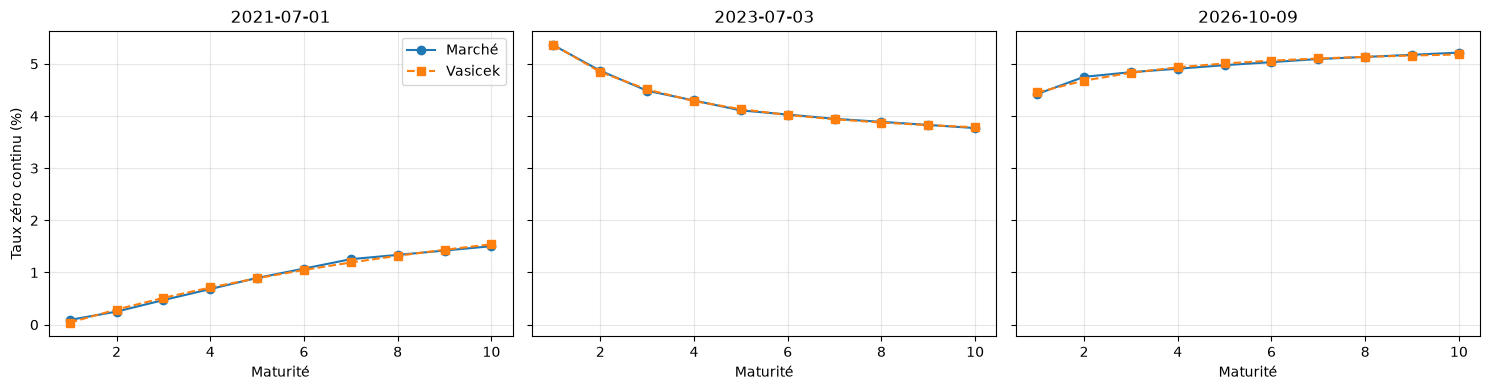

,date,r0,a,b (Q),RMSE (pb)
0,2021-07-01,-0.0024,0.17,0.0330,3.6807
1,2023-07-03,0.0620,0.77,0.0343,1.6005
2,2026-10-09,0.0411,0.68,0.0537,3.2712


In [13]:
curves = pd.read_csv("../data/us_par_yields.csv", index_col=0, parse_dates=True)
curves.columns = curves.columns.astype(int)

rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, d in zip(axes, ["2021-07-01", "2023-07-03", str(curves.index[-1].date())]):
    row = curves.loc[:d].iloc[-1]
    m_us, p_us = par_on_annual_grid(row.index.values, row.values)
    _, z_us = bootstrap_par_curve(m_us, p_us)
    R_us = np.log(1 + z_us)
    f = calibrate_vasicek_curve(m_us, R_us, 0.01, np.arange(0.02, 3.0, 0.01))
    R_f = vasicek_zero_rate(f["r0"], f["a"], f["b"], f["sigma"], m_us)
    ax.plot(m_us, 100 * R_us, "o-", label="Marché"); ax.plot(m_us, 100 * R_f, "s--", label="Vasicek")
    ax.set_title(str(row.name.date())); ax.set_xlabel("Maturité"); ax.grid(alpha=0.3)
    rows.append({"date": row.name.date(), "r0": f["r0"], "a": f["a"], "b (Q)": f["b"],
                 "RMSE (pb)": 1e4 * f["rmse"]})
axes[0].set_ylabel("Taux zéro continu (%)"); axes[0].legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(4)

## Calibration historique sous la mesure $P$

###  Différence entre mesure $P$ et mesure $Q$

- Mesure **$Q$ (risque-neutre)** : utilisée pour le **pricing**.
- Mesure **$P$ (historique)** : utilisée pour la **prévision** et le **risque**.

Les paramètres $(a, b, \sigma)$ peuvent être **très différents** entre les deux mesures.

###  Méthode

On utilise le taux 1 an comme proxy du taux court, discrétisé mensuellement. L'EDS devient :

$$
r_{t+\Delta t} - r_t = a(b - r_t)\Delta t + \varepsilon_t
$$

C'est une **régression linéaire** :

$$
r_{t+\Delta t} - r_t = \underbrace{ab\Delta t}_{\alpha} - \underbrace{a\Delta t}_{\beta} r_t + \varepsilon_t
$$

On estime $\alpha, \beta$ par OLS, puis :

$$
a = -\frac{\beta}{\Delta t}, \qquad b = -\frac{\alpha}{\beta}, \qquad \sigma = \frac{\text{std}(\varepsilon)}{\sqrt{\Delta t}}
$$

### Résultats

| Période | $a$ | $b$ | $\sigma$ | Demi-vie (ans) | Écart-type stationnaire |
|---------|-----|-----|----------|----------------|--------------------------|
| 1976-2007 | ... | ... | ... | ... | ... |
| Échantillon complet | ... | ... | ... | ... | ... |

### Observations

- Les paramètres **varient** selon la période.
- La demi-vie et l'écart-type stationnaire aussi.
- Conclusion : le modèle Vasicek est **non-stationnaire** dans la réalité.

C'est un point crucial pour la gestion du risque.

In [14]:
short = curves[1]                                       # taux 1 an comme proxy du taux court
monthly = short.groupby(short.index.to_period("M")).last().values

rows = []
for label, sl in [("1976-2007", slice(0, 12 * 32)), ("Échantillon complet", slice(None))]:
    a_h, b_h, s_h = fit_vasicek_ols(monthly[sl], 1 / 12)
    rows.append({"période": label, "a": a_h, "b (P)": b_h, "σ": s_h,
                 "demi-vie (ans)": np.log(2) / a_h, "écart-type stationnaire": s_h / np.sqrt(2 * a_h)})
pd.DataFrame(rows).round(4)

,période,a,b (P),σ,demi-vie (ans),écart-type stationnaire
0,1976-2007,0.1582,0.0566,0.0200,4.3820,0.0355
1,Échantillon complet,0.1002,0.0431,0.0163,6.9162,0.0364


## Pricing d'obligations et swaps avec le modèle calibré

### Objectif

Utiliser les paramètres Vasicek calibrés sur une courbe réelle pour pricer :

1. Une **obligation à 7 ans, coupon 5 %**.
2. Des **taux swap** de maturités 3, 5, 7, 10 ans.

### Pricing

- Obligation : somme des cashflows actualisés par la courbe zéro Vasicek.
- Swap : taux fixe qui annule la valeur du swap (par swap rate).

### Comparaison marché vs modèle

| Produit | Marché | Vasicek | Écart (pb) |
|---------|--------|---------|------------|
| Obligation 7 ans, c=5 % | ... | ... | — |
| Swap 3 ans | ... | ... | ... |
| Swap 5 ans | ... | ... | ... |
| Swap 7 ans | ... | ... | ... |
| Swap 10 ans | ... | ... | ... |

### Interprétation

- Écarts de quelques **points de base** → cohérents.
- Le modèle est **utilisable** pour pricer des produits simples.
- Mais attention : les écarts augmentent souvent avec la maturité (limite structurelle).

In [15]:
z_model = vasicek_zero_annual(fit["r0"], fit["a"], fit["b"], fit["sigma"], mats)

t7, cf7 = cashflows(100, 0.05, 7)
print(f"Obligation 7 ans, coupon 5 % : marché {price_with_curve(t7, cf7, mats, zeros):.4f}"
      f" | Vasicek {price_with_curve(t7, cf7, mats, z_model):.4f}")

for T_ in [3, 5, 7, 10]:
    s_mkt = par_swap_rate(swap_schedule(T_), mats, zeros)
    s_mod = par_swap_rate(swap_schedule(T_), mats, z_model)
    print(f"Taux swap {T_:>2} ans : marché {s_mkt:.4%} | Vasicek {s_mod:.4%} | écart {1e4 * (s_mod - s_mkt):+.1f} pb")

Obligation 7 ans, coupon 5 % : marché 109.2661 | Vasicek 109.3615
Taux swap  3 ans : marché 2.9000% | Vasicek 2.9292% | écart +2.9 pb
Taux swap  5 ans : marché 3.2500% | Vasicek 3.2521% | écart +0.2 pb
Taux swap  7 ans : marché 3.5000% | Vasicek 3.4848% | écart -1.5 pb
Taux swap 10 ans : marché 3.7000% | Vasicek 3.7239% | écart +2.4 pb


## Pricing d'un call sur zéro-coupon par Monte-Carlo

### Produit

- **Option call européenne** de maturité $t_{\text{opt}} = 1$ an.
- **Sous-jacent** : zéro-coupon de maturité $T_{\text{bond}} = 5$ ans.
- **Strike** $K$ : prix forward du zéro-coupon, i.e.
$$
K = \frac{P(0, T_{\text{bond}})}{P(0, t_{\text{opt}})}
$$

### Méthode Monte-Carlo

1. Simuler $r(t_{\text{opt}})$ à l'aide du schéma exact.
2. Calculer le prix du zéro-coupon en $t_{\text{opt}}$ :
$$
P(t_{\text{opt}}, T_{\text{bond}}) = A(T_{\text{bond}} - t_{\text{opt}})\, e^{-B(T_{\text{bond}} - t_{\text{opt}})\, r(t_{\text{opt}})}
$$
3. Payoff actualisé :
$$
\text{Payoff} = e^{-\int_0^{t_{\text{opt}}} r(s)\,ds}\,\max\!\big(P(t_{\text{opt}}, T_{\text{bond}}) - K,\ 0\big)
$$
4. Moyenne sur $N$ trajectoires + erreur-type.

### Effet de $\sigma$ sur le prix du call

On fait varier $\sigma$ et on trace le prix du call :

- $\sigma \uparrow$ ⇒ prix du call $\uparrow$ (plus de volatilité = plus de valeur pour l'option).

### Note importante

Dans Vasicek, il existe une **formule fermée** pour ce type d'option (formule de Jamshidian, 1989). Ici, nous utilisons Monte-Carlo, mais on pourrait comparer les deux pour valider.

### Résultats

- Le prix augmente avec $\sigma$ de manière convexe.
- Les **barres d'erreur** (±2 erreurs-types) restent faibles → estimation précise.
- La courbe peut être comparée à la formule de Jamshidian pour valider la simulation.

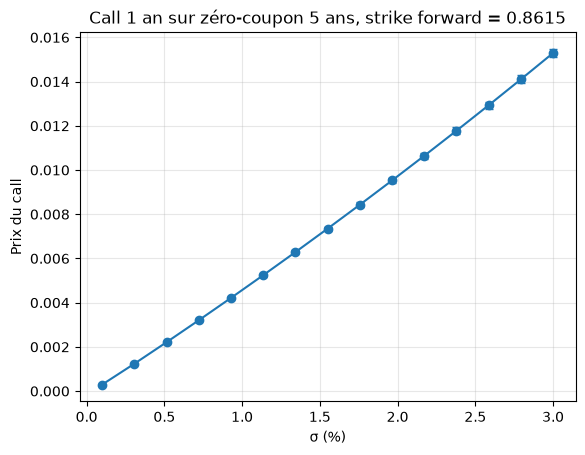

In [16]:
t_opt, T_bond = 1, 5
P1 = vasicek_zc_price(r0, a, b, sigma, t_opt)
P5 = vasicek_zc_price(r0, a, b, sigma, T_bond)
K = P5 / P1                                             # strike à la monnaie forward

sigmas = np.linspace(0.001, 0.03, 15)
prices, errors = zip(*[mc_zc_call(r0, a, b, s, t_opt, T_bond, K) for s in sigmas])

plt.errorbar(sigmas * 100, prices, yerr=2 * np.array(errors), fmt="o-", capsize=3)
plt.xlabel("σ (%)"); plt.ylabel("Prix du call")
plt.title(f"Call {t_opt} an sur zéro-coupon {T_bond} ans, strike forward = {K:.4f}")
plt.grid(alpha=0.3); plt.show()

## Conclusion générale

Ce notebook a illustré de manière complète le **modèle de Vasicek** :

### Théorie
- EDS à retour à la moyenne.
- Solution explicite : loi normale à chaque instant.
- Moments, variance stationnaire, taux long terme $R_\infty$.

### Simulation
- Schéma exact (précis) vs schéma d'Euler (convergent).
- Validation empirique des moments théoriques.
- Analyse de la distribution (histogrammes vs densité).

### Sensibilité
- Rôle de $a$ (vitesse de rappel) et $\sigma$ (volatilité).
- Effet sur la courbe des taux et la sensibilité $B(\tau)$.

### Calibration
- Mesure $Q$ (pricing) vs mesure $P$ (historique).
- Données synthétiques et réelles (US).
- Limites : instabilité temporelle, rigidité.

### Applications
- Pricing d'obligations, swaps, options.
- Comparaison marché vs modèle : écarts de quelques pb.

---

## Limites du modèle de Vasicek

1. **Taux négatifs autorisés** (loi normale) → irréaliste dans certains contextes.
2. **Paramètres instables dans le temps** → difficulté de gestion long terme.
3. **Forme de courbe rigide** (structure affine) → pas assez flexible.
4. **Volatilité constante** → ne capture pas les "smiles" observés sur le marché.
5. **Un seul facteur** → ne capture pas les mouvements de "twist" de la courbe.

---

## Extensions classiques

| Modèle | Amélioration |
|--------|--------------|
| **CIR** (1985) | Garantit $r(t) \geq 0$ (racine carrée). |
| **Hull-White** (1990) | Paramètres dépendants du temps → calibration exacte. |
| **Black-Karasinski** (1991) | Modélise $\ln r(t)$ → évite les taux négatifs. |
| **Longstaff-Schwartz** (1992) | Deux facteurs → capture le "twist". |
| **HJM** (1992) | Modélise toute la courbe forward. |

---

## Références

- Vasicek, O. (1977). *An equilibrium characterization of the term structure*. Journal of Financial Economics.
- Hull, J. (2018). *Options, Futures, and Other Derivatives*. Pearson.
- Brigo, D. & Mercurio, F. (2006). *Interest Rate Models — Theory and Practice*. Springer.
- Jamshidian, F. (1989). *An exact bond option formula*. Journal of Finance.